In [1]:
import pandas as pd
df = pd.read_csv("../data/creditcard.csv")
print(df.shape)

(284807, 31)


In [2]:
print(df.head())
print("Missing values:", df.isnull().sum().sum())

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 

In [3]:
print(df["Class"].value_counts())
print(df["Class"].value_counts(normalize=True) * 100)

Class
0    284315
1       492
Name: count, dtype: int64
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


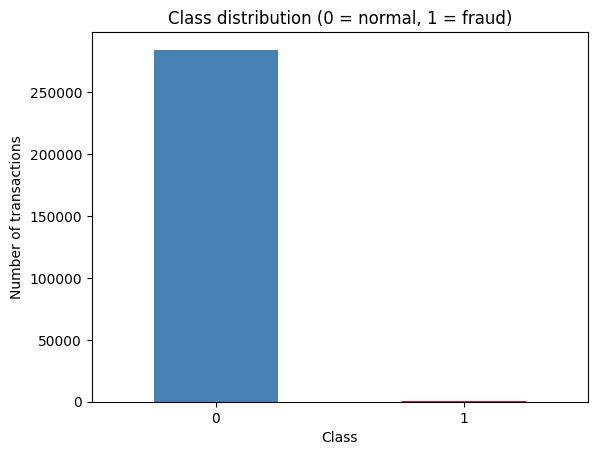

In [4]:
import matplotlib.pyplot as plt
import os

os.makedirs("../images", exist_ok=True)

df["Class"].value_counts().plot(kind="bar", color=["steelblue", "crimson"])
plt.title("Class distribution (0 = normal, 1 = fraud)")
plt.xticks(rotation=0)
plt.ylabel("Number of transactions")
plt.savefig("../images/class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
print(df.groupby("Class")["Amount"].describe())

          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      284315.0   88.291022  250.105092  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.211321  256.683288  0.0  1.00   9.25  105.89   2125.87


In [6]:
corr = df.corr()["Class"].drop("Class").sort_values()
print(corr.head(5))
print(corr.tail(5))

V17   -0.326481
V14   -0.302544
V12   -0.260593
V10   -0.216883
V16   -0.196539
Name: Class, dtype: float64
V19    0.034783
V21    0.040413
V2     0.091289
V4     0.133447
V11    0.154876
Name: Class, dtype: float64


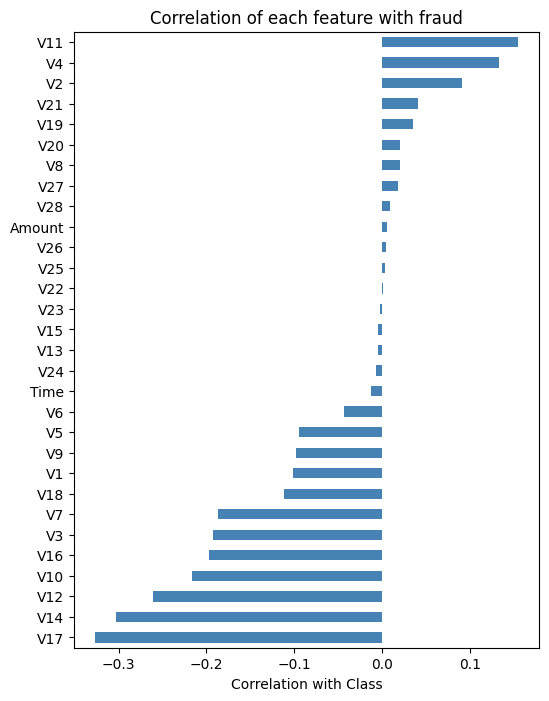

In [7]:
corr.plot(kind="barh", figsize=(6, 8), color="steelblue")
plt.title("Correlation of each feature with fraud")
plt.xlabel("Correlation with Class")
plt.savefig("../images/feature_correlation.png", dpi=150, bbox_inches="tight")
plt.show()